# EDA Exercise

In this exercise, you will read in your data, do some preliminary data cleaning, and do EDA to better understand your data.

[The dataset]( http://ddc-datascience.s3.amazonaws.com/auto-mpg.csv ) for this exercise is saved in an Amazon Web Services ( AWS ) S3 bucket. The original source and details about this dataset can be found [here](https://archive.ics.uci.edu/ml/datasets/Auto+MPG).

Below are the steps you'll need to perform for the EDA. Make sure to use text blocks to organize your analysis.  Discuss any trends/relationships/issues you discover at each step in the analysis.

1. Import `pandas` as `pd`, `matplotlib.pyplot as plt`, and `seaborn as sns`.
1. Read in the csv file found at http://ddc-datascience.s3.amazonaws.com/auto-mpg.csv .
1. Understand your data by using at least 4 pandas methods (e.g., `.head()`).
1. Make a copy of your data frame. In your copy, remove any rows that contain null values.  
1. Calculate summary statistics on one or more columns.
1. Generate at least 3 univariate plots.
1. Generate a correlation plot.
1. Generate a pairplot.
9. If we were going to build a predictive model ( supervised learning ) using this dataset, what do you think would be a good response ( aka target ) variable and why?

## Step 1: Import



Import pandas as pd, matplotlib.pyplot as plt, and seaborn as sns.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Step 2: Get data


Read in the csv file found at http://ddc-datascience.s3.amazonaws.com/auto-mpg.csv.


In [2]:
url= "http://ddc-datascience.s3.amazonaws.com/auto-mpg.csv"
df= pd.read_csv(url)


## Step 3: Understand data


Understand your data by using at least 4 pandas methods (e.g., .head()).


have learned
  - head: first five rows
  - tail: last five rows
  - shape: shape of data, amount of rows,columns
  - size: multiple of rows x columns
  - info:
    - display the columns and, amount of values in those rows and the data type

In [4]:
df.sample(5) # this show 5 random rows, .head()show the first five ros

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
60,20.0,4,140.0,90.0,2408,19.5,72,1
286,17.6,8,302.0,129.0,3725,13.4,79,1
239,30.0,4,97.0,67.0,1985,16.4,77,3
261,18.1,6,258.0,120.0,3410,15.1,78,1
30,28.0,4,140.0,90.0,2264,15.5,71,1


In [5]:
df.describe() #count, mean, std, min, quartiles, and max for every numeric column

# count: show if anything is missing ex. Every column has 398 values except horsepower, which has 392.
# 50%- is the data median


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [7]:
df.isnull().sum() # count the missing values per column

,0
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model year,0
origin,0


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


## Step 4: Copy and clean


Make a copy of your data frame. In your copy, remove any rows that contain null values.


In [12]:
backup_df= df.copy()
backup_df= backup_df.dropna(subset=['horsepower'])

#to remove nulls values need (.dropna) & subset=[] )

In [14]:
backup_df.isnull().sum().sort_values() # this check for null values

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model year,0
origin,0


## Step 5: Summary stats


Calculate summary statistics on one or more columns.


In [15]:
backup_df.describe()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592,1.576531
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737,0.805518
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000,1.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


## Step 6: Univariate plots
  - This shows what does a column look like in graph form


Generate at least 3 univariate plots.


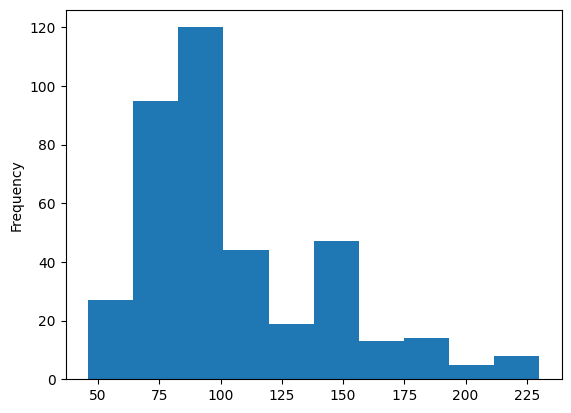

In [30]:
#this display a histogram graph
backup_df['horsepower'].plot(kind='hist', bins=10) ;

# kind='hist'
# a histogram better at showing a range.
# and the freqency of those number within the range




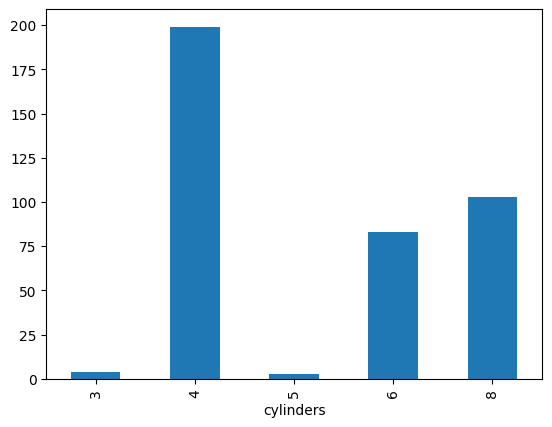

In [33]:
# show a Bar chart
# show how many car fall into each categories
backup_df['cylinders'].value_counts().sort_index().plot(kind='bar') ;

# backup_df['horsepower'].value_counts().sort_index().plot(kind='bar') ;
# if yse'horsepower as a bar graph because it hard to group the numbers.
# it will have to many categories to chart.

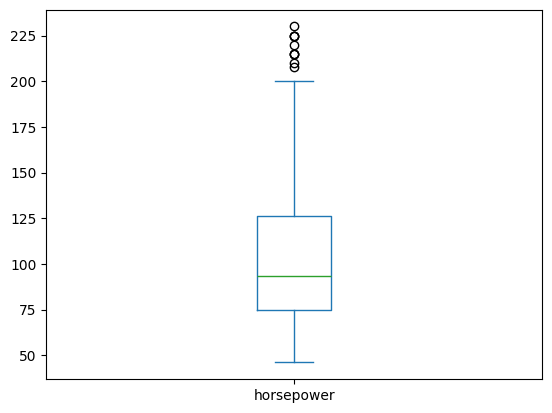

In [23]:
# this display a box plot
# box plot show the information found in .describe()
backup_df['horsepower'].plot(kind='box') ;

#output- there dot outside the box plot show car that outside

## Step 7: Bivariate plot (1/2)


Generate a correlation plot.


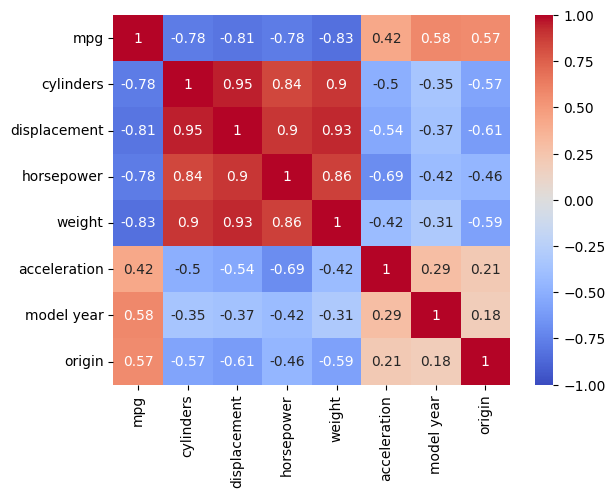

In [39]:
# this calculate the correlation matrix
corr_matrix = backup_df.corr (numeric_only=True) ;

#draw it as a heatmap (the picture)
sns.heatmap(corr_matrix,
            annot=True,
            cmap='coolwarm',
            vmin=-1, vmax=1
            ) ;

# Both 1 and -1 mean strong correlation.
# Close to 1: strong, and they move the same direction. As one goes up, the other goes up.
# Close to -1: strong, and they move in opposite directions. As one goes up, the other goes down.
# Close to 0: weak or no straight-line relationship. This is what “low correlation” means.

## Step 8: Bivariate plot (2/2)


Generate a pairplot.


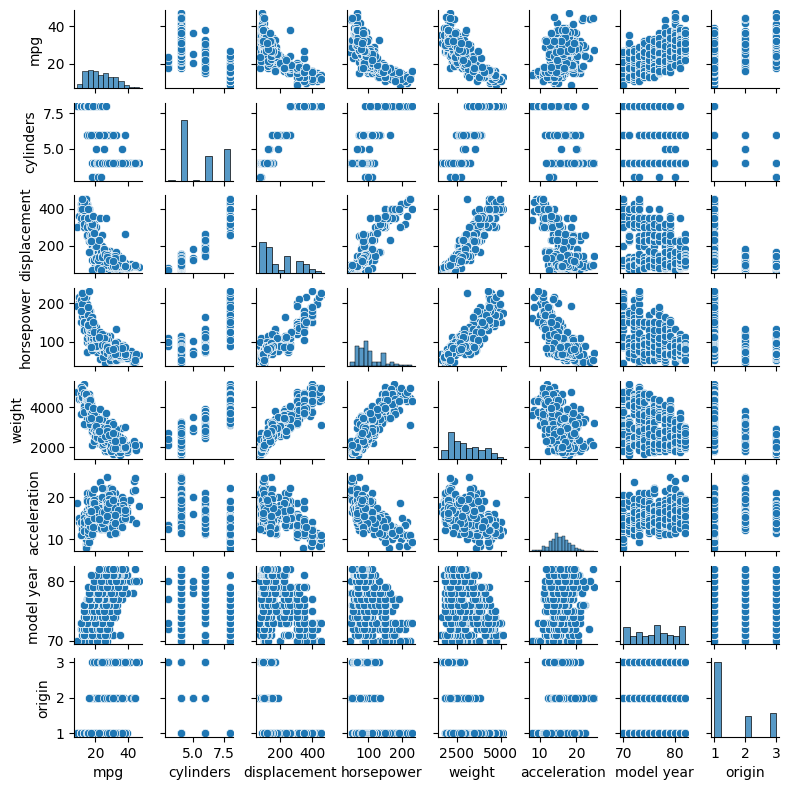

In [45]:
sns.pairplot(backup_df,
             height=1.0,



             ) ;

## Step 9: Conclusion


If we were going to build a predictive model ( supervised learning ) using this dataset, what do you think would be a good response ( aka target ) variable and why?

- I would chose `mpg` as the target beacuase it the thing most people want to know when buying a car.

- I would choose `weight` because it has strongest correlation with `mpg`       (-0.83) and `model year` (0.58) as the variable.

